# Basics > Central Limit Theorem

<div class="alert alert-info">Using random sampling to illustrate the Central Limit Theorem</div>

The Central Limit Theorem (CLT) says that the sum (or mean) of a large number of independent draws from a population with a finite mean and variance is approximately normally distributed, whatever the shape of the population. Almost every test in Basics (single mean, compare means, proportions) relies on this.

`rsm.basics.clt` draws `m` samples of size `n` from a population and shows the distribution of their sums or means. For a population with mean $\mu$ and standard deviation $\sigma$:

* sample means: mean $\mu$, standard deviation $\sigma / \sqrt{n}$ (the standard error)
* sample sums: mean $n\mu$, standard deviation $\sqrt{n}\,\sigma$

These hold at every sample size; what depends on `n` is how close to normal the distribution is.

In [1]:
import pyrsm as rsm

In [2]:
## setup pyrsm for autoreload
%reload_ext autoreload
%autoreload 2
%aimport pyrsm

## Example 1: a skewed population and small samples

An Exponential population with rate 1 (mean 1, standard deviation 1) is strongly skewed. Draw 1,000 samples of size 2 and look at their means (seed 1234 makes the draw reproducible):

In [3]:
clt = rsm.basics.clt("Exponential", n=2, m=1000, expo_rate=1, seed=1234)
clt.summary(stat="mean")

Central Limit Theorem
Distribution: Exponential
Rate        : 1
Sample size : 2
# of samples: 1,000
Statistic   : sample means
Seed        : 1234

Sample means:
            Mean  St. dev
Simulated  1.025    0.717
CLT            1    0.707

CLT: with a sample size of 2, the sample means have mean 1 and st. dev 0.707; their distribution gets closer to normal as the sample size grows.


The mean and standard deviation of the sample means already match the CLT (1 and $1/\sqrt{2} = 0.707$), but the histogram is still skewed to the right and the density does not follow the normal curve (black). The subtitles show the settings: the population's parameters above the two individual samples, and `n` and `m` above the sample means.

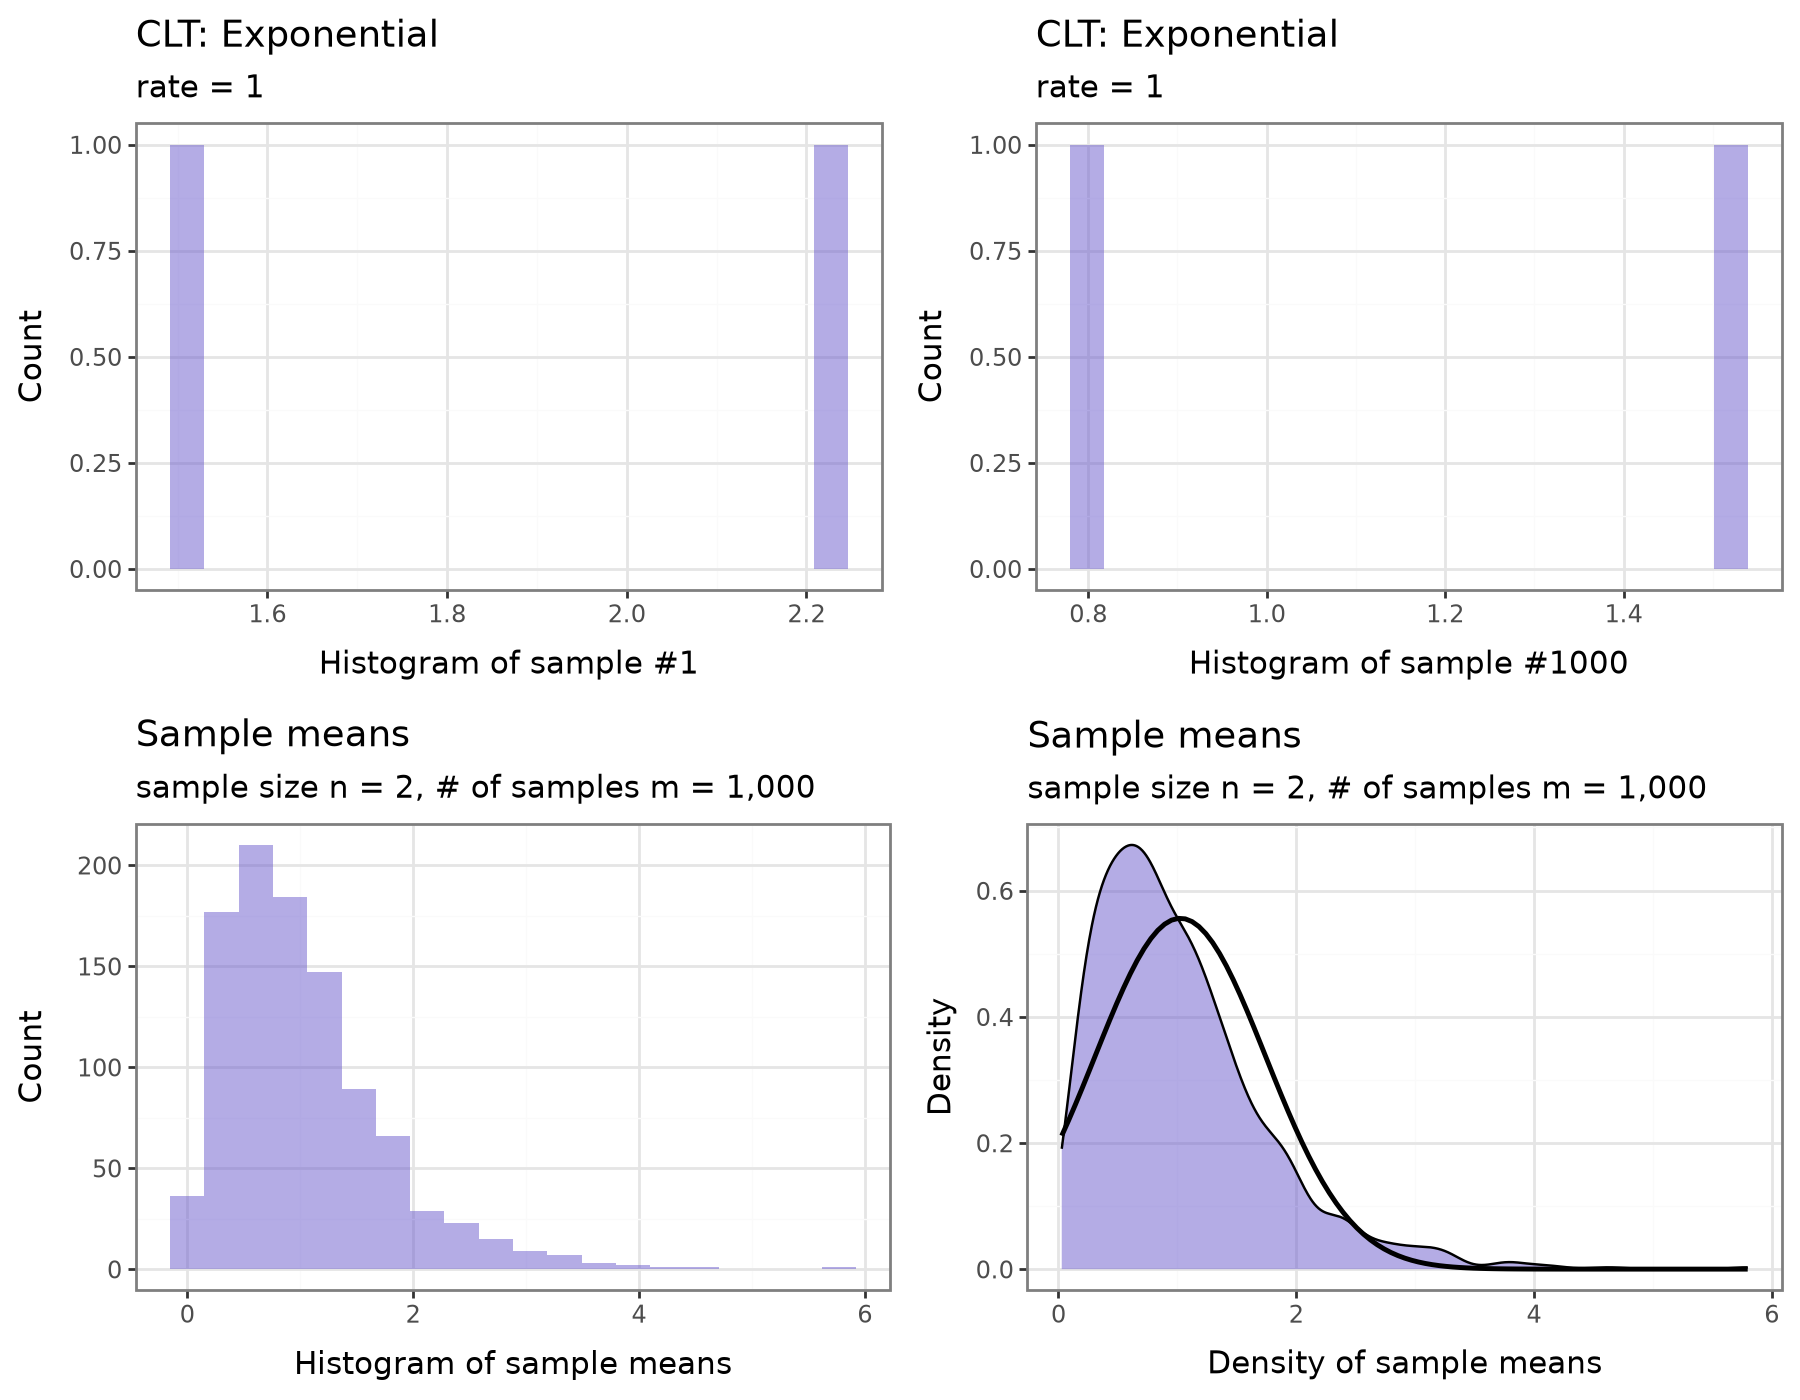

In [4]:
clt.plot(stat="mean", bins=20)

## Example 2: the same population, larger samples

Keep everything the same but use samples of size 30:

Central Limit Theorem
Distribution: Exponential
Rate        : 1
Sample size : 30
# of samples: 1,000
Statistic   : sample means
Seed        : 1234

Sample means:
            Mean  St. dev
Simulated  1.002     0.18
CLT            1    0.183

CLT: with a sample size of 30, the sample means have mean 1 and st. dev 0.183; their distribution gets closer to normal as the sample size grows.


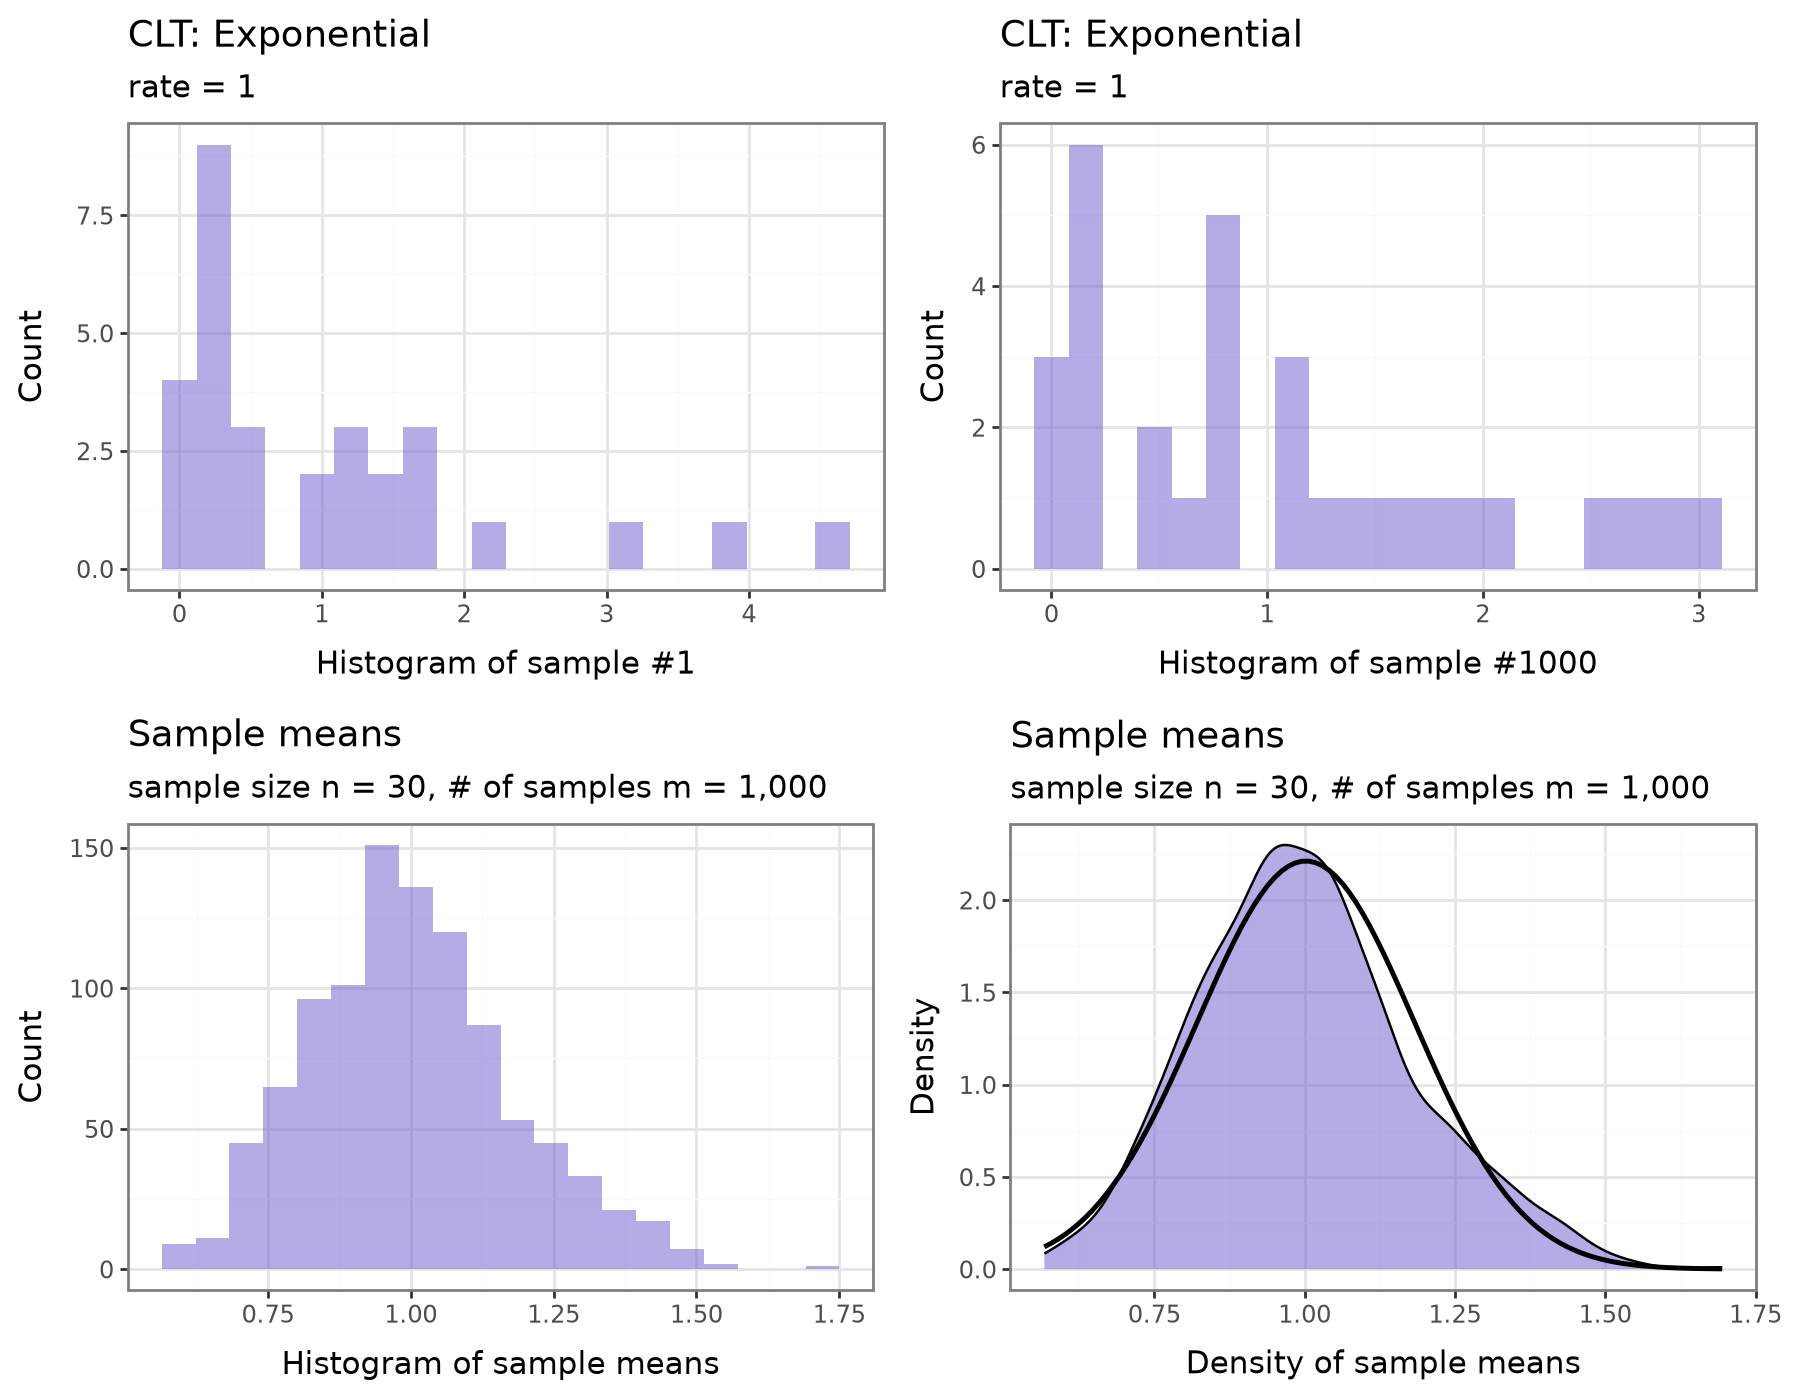

In [5]:
clt = rsm.basics.clt("Exponential", n=30, m=1000, expo_rate=1, seed=1234)
clt.summary(stat="mean")
clt.plot(stat="mean", bins=20)

Each individual sample (top row) is still skewed, because the population is. The sample means (bottom row) are now close to a bell curve, with a spread of about $1/\sqrt{30} = 0.183$. Quadrupling the sample size halves the standard error.

## Example 3: sums of binomial samples

A Binomial population with size 10 and probability 0.2 (mean 2, standard deviation $\sqrt{10 \times 0.2 \times 0.8} = 1.265$) takes only a few whole numbers and is skewed. Sum samples of size 100:

Central Limit Theorem
Distribution: Binomial
Size        : 10
Prob        : 0.2
Sample size : 100
# of samples: 1,000
Statistic   : sample sums
Seed        : 1234

Sample sums:
              Mean  St. dev
Simulated  200.179   12.503
CLT            200   12.649

CLT: with a sample size of 100, the sample sums have mean 200 and st. dev 12.649; their distribution gets closer to normal as the sample size grows.


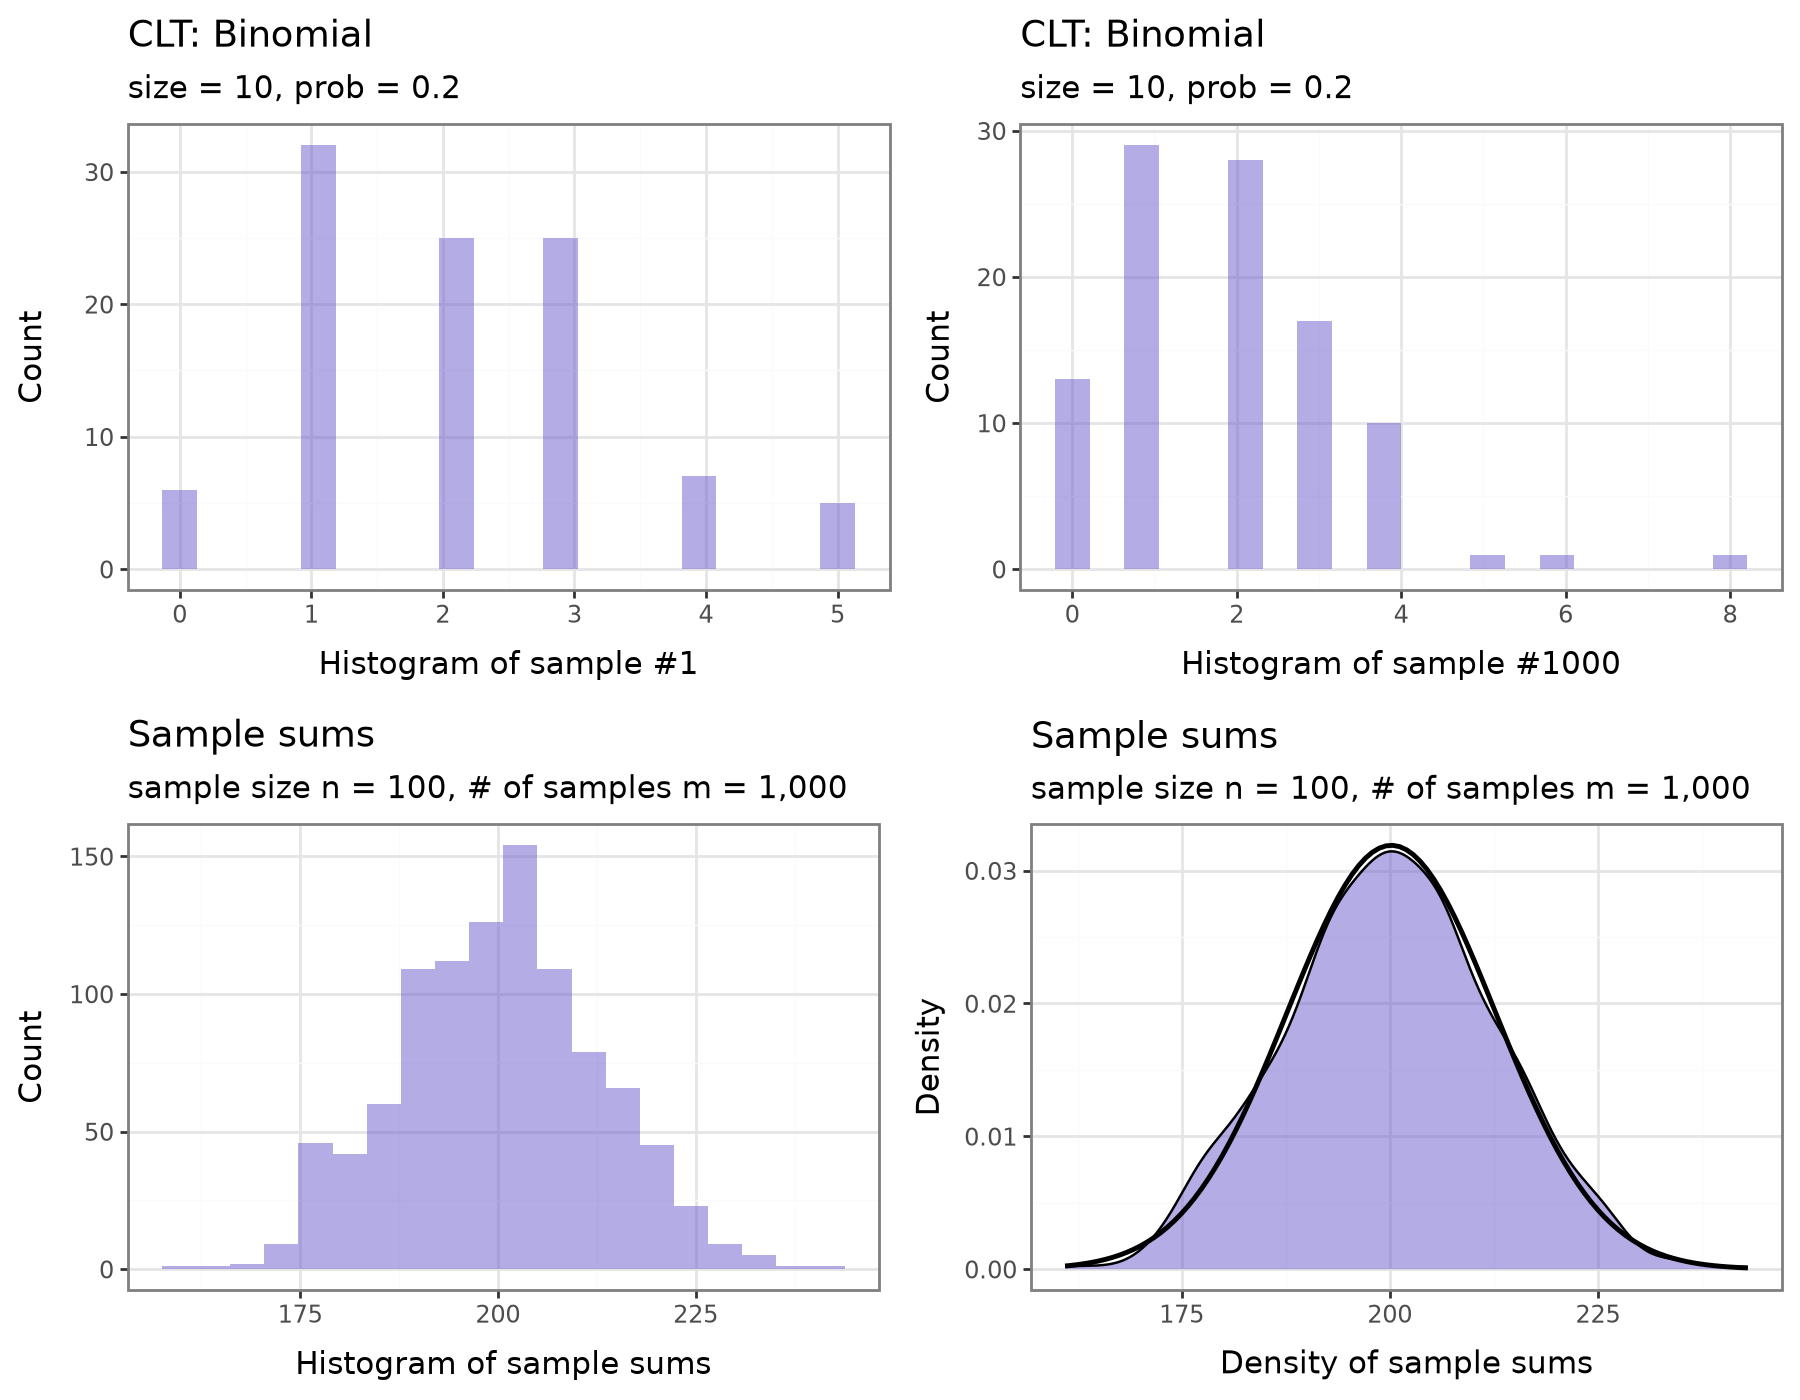

In [6]:
clt = rsm.basics.clt("Binomial", n=100, m=1000, binom_size=10, binom_prob=0.2, seed=1234)
clt.summary(stat="sum")
clt.plot(stat="sum", bins=20)

The sums are very close to normal, with mean $100 \times 2 = 200$ and standard deviation $\sqrt{100} \times 1.265 = 12.649$, as the CLT predicts for sums.

## Things to try

* `Uniform` with a sample size of 2: the means form a triangle; at 5 they already look roughly normal.
* `Normal`: the sample means are normal at every sample size, because the population already is.
* `stat="sum"` versus `stat="mean"`: the shape is the same, only the scale changes (by a factor `n`).
* A larger `m` instead of a larger `n`: the histograms get smoother, but not more normal.

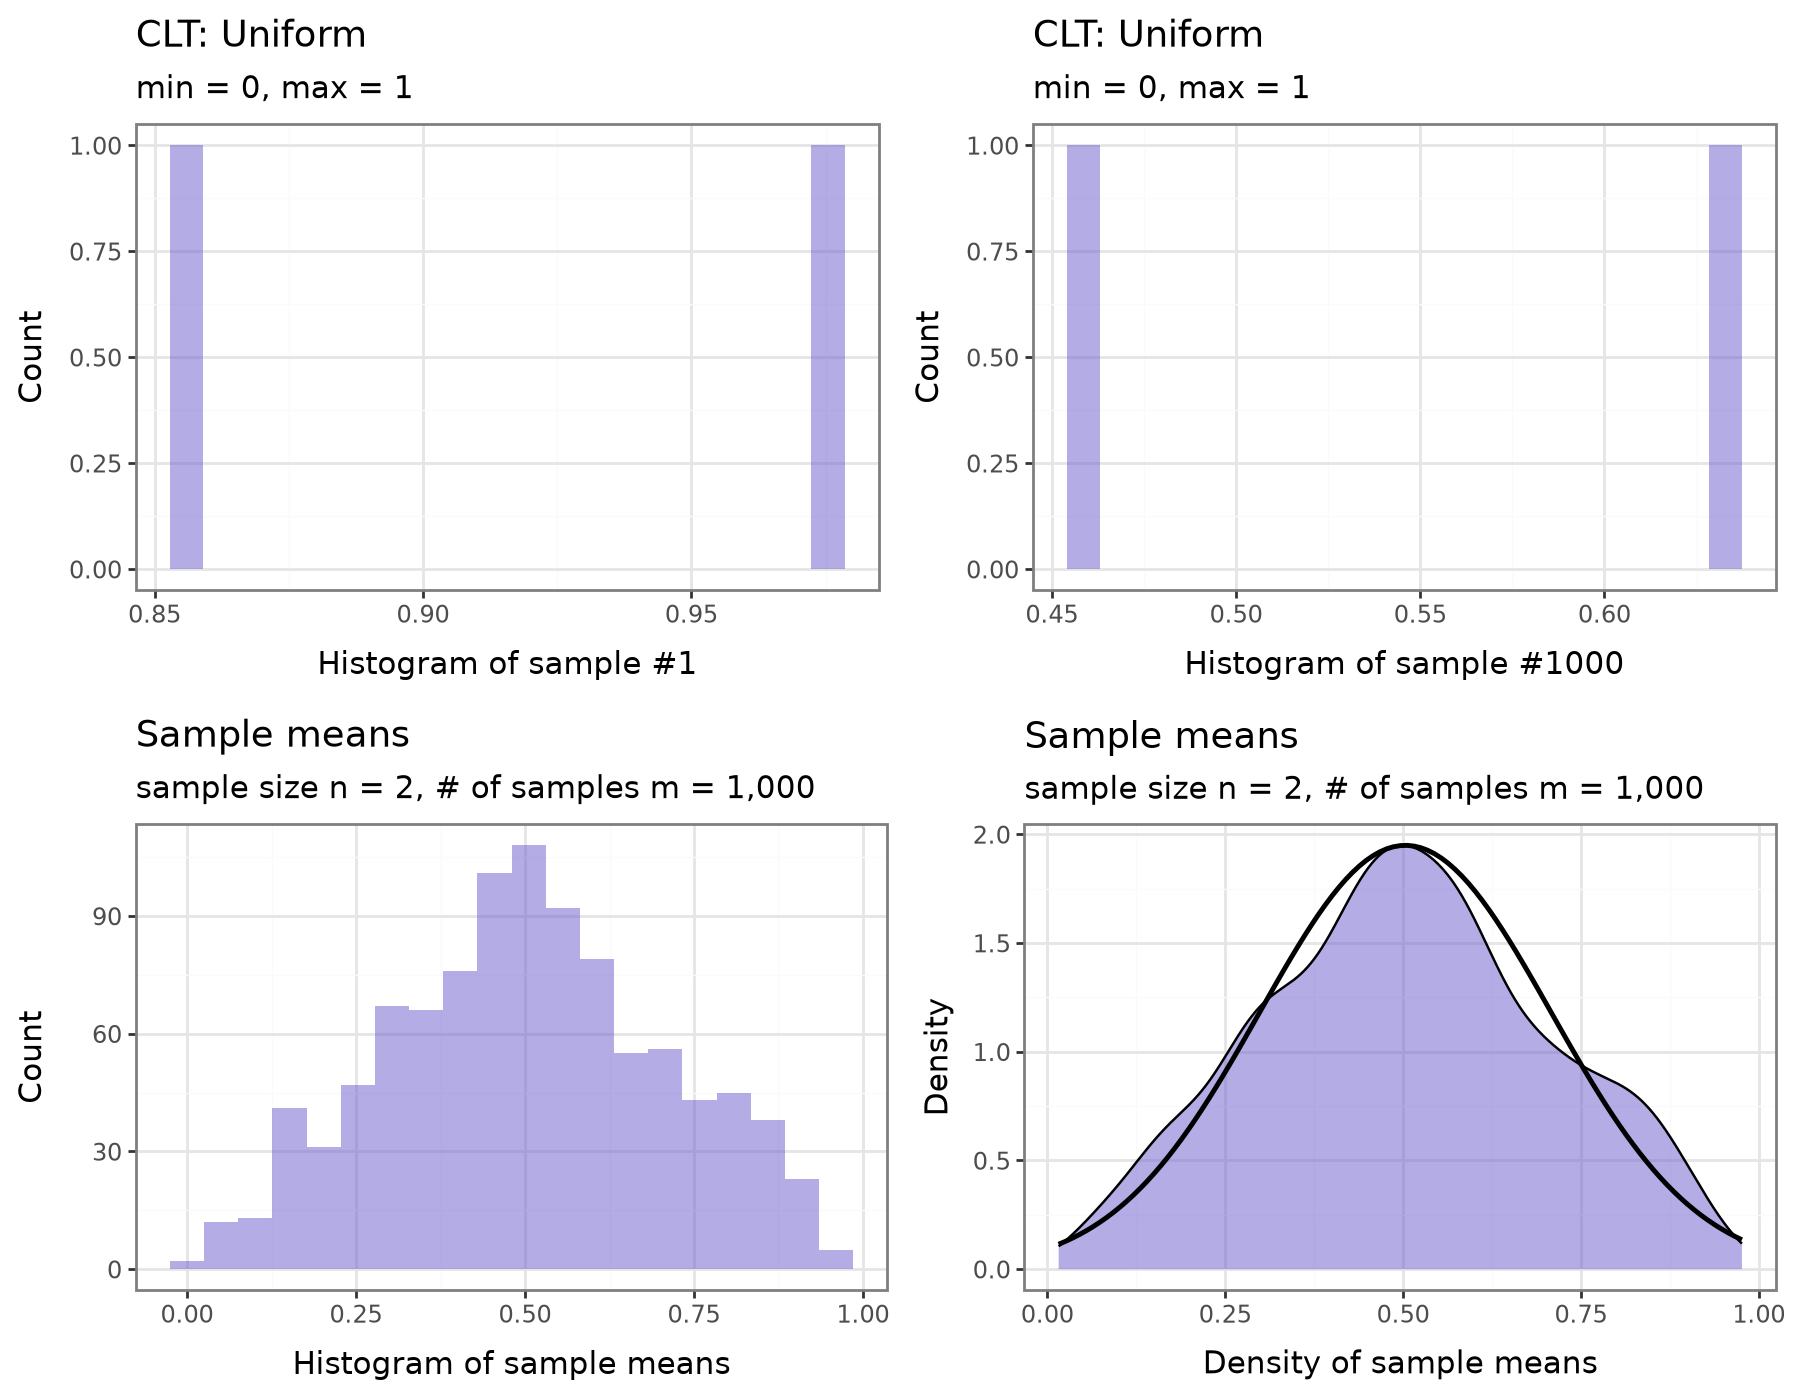

In [7]:
clt = rsm.basics.clt("Uniform", n=2, m=1000, unif_min=0, unif_max=1, seed=1234)
clt.plot(stat="mean", bins=20)

© Vincent Nijs (2026)